In [2]:
import importlib.util
import sys
import subprocess

def check_and_install(package_name):
    # Check if the package is installed
    spec = importlib.util.find_spec(package_name)
    
    if spec is None:
        # Install if it is not found
        print(f" '{package_name}' not found. Installing now...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])
    else:
        print(f" '{package_name}' is already installed.")

check_and_install("numpy")
check_and_install("matplotlib")
check_and_install("cmasher")
check_and_install("astropy")
check_and_install("scipy")
check_and_install("pandas")

 'numpy' is already installed.
 'matplotlib' is already installed.
 'cmasher' is already installed.
 'astropy' is already installed.
 'scipy' is already installed.
 'pandas' is already installed.


In [3]:
# import libraries
from math import log10, floor
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colours
import cmasher as cm
import pandas as pd
from astropy.io import ascii, fits
from astropy.table import Table, join
from scipy.odr import *

C:\Users\User\AppData\Local\Temp\ipykernel_3060\3503174193.py:10: DeprecationWarning: `scipy.odr` is deprecated as of version 1.17.0 and will be removed in SciPy 1.19.0. Please use `https://pypi.org/project/odrpack/` instead.
  from scipy.odr import *


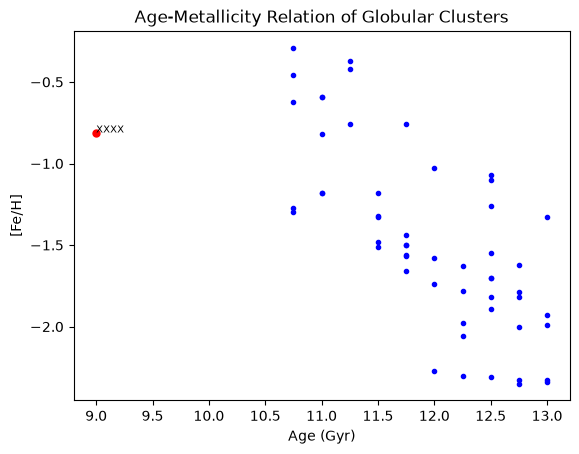

In [4]:
vbt_table = ascii.read('vandenBerg_table2.csv', format='csv')

gc_id = vbt_table['#NGC']
gc_age = vbt_table['Age']
gc_FeH = vbt_table['FeH']

gc_age = np.array(gc_age, dtype=float)
gc_FeH = np.array(gc_FeH, dtype=float)

fit = np.polyfit(gc_age, gc_FeH, 1)
fe_trend = np.polyval(fit, gc_age)
residuals = gc_FeH - fe_trend
spread = np.std(residuals)

if spread > 0:
    deviation = residuals / spread
else:
    deviation = np.zeros(len(gc_id), dtype=int)

arm_outlier = np.abs(deviation) > 2

plt.plot(gc_age, gc_FeH, 'o', markersize=3, color='blue')
plt.plot(gc_age[arm_outlier], gc_FeH[arm_outlier], 'o', markersize=5, color='red', label='Outliers')

for i in range(len(gc_id)):
    if arm_outlier[i]:
        plt.annotate(str(gc_id[i]), (gc_age[i], gc_FeH[i]), fontsize=7)

plt.title('Age-Metallicity Relation of Globular Clusters')
plt.xlabel('Age (Gyr)')
plt.ylabel('[Fe/H]')

plt.margins(x=0.05, y=0.05)

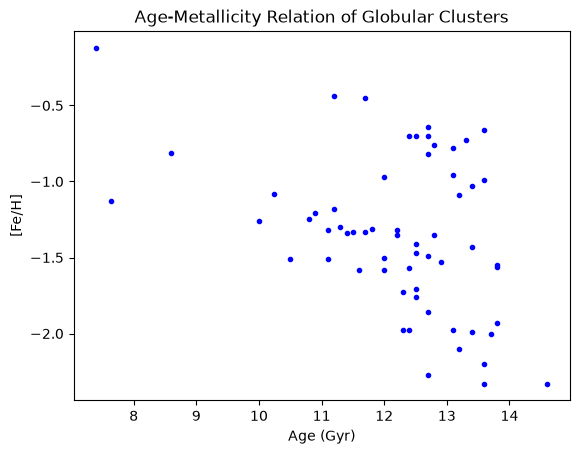

In [5]:
krause21_data = ascii.read('krause21.csv', format='csv')

gc_id = krause21_data['Object']
gc_age = krause21_data['Age']
gc_FeH = krause21_data['FeH']

gc_age = np.array(gc_age, dtype=float)
gc_FeH = np.array(gc_FeH, dtype=float)

fit = np.polyfit(gc_age, gc_FeH, 1)
fe_trend = np.polyval(fit, gc_age)
residuals = gc_FeH - fe_trend
spread = np.std(residuals)

if spread > 0:
    deviation = residuals / spread
else:
    deviation = np.zeros(len(gc_id), dtype=int)

arm_outlier = np.abs(deviation) > 2

plt.plot(gc_age, gc_FeH, 'o', markersize=3, color='blue')
plt.plot(gc_age[arm_outlier], gc_FeH[arm_outlier], 'o', markersize=3, color='red', label='Outliers')

for i in range(len(gc_id)):
    if arm_outlier[i]:
        plt.annotate(str(gc_id[i]), (gc_age[i], gc_FeH[i]), fontsize=4)

plt.title('Age-Metallicity Relation of Globular Clusters')
plt.xlabel('Age (Gyr)')
plt.ylabel('[Fe/H]')

plt.margins(x=0.05, y=0.05)

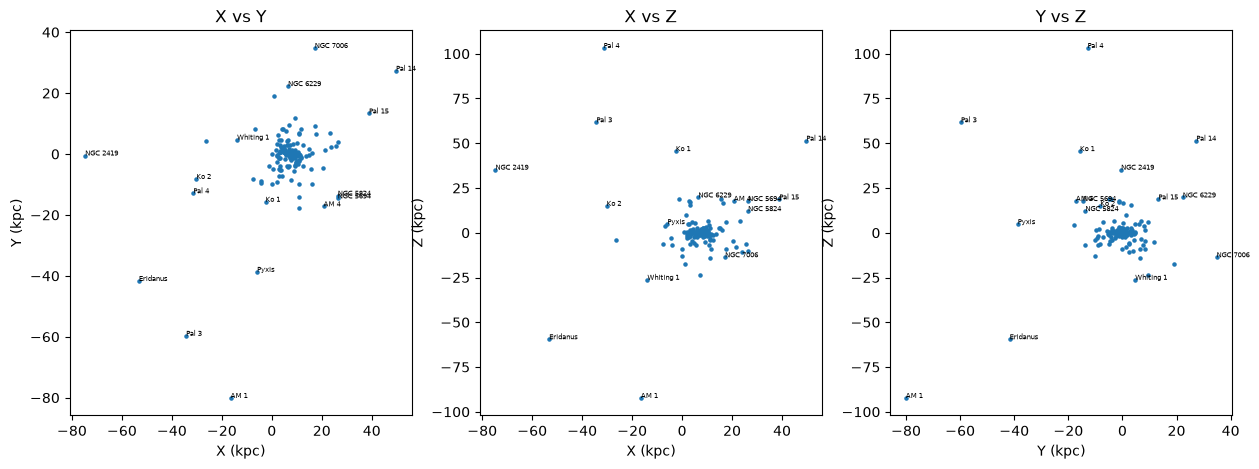

In [6]:
gc = ascii.read('HarrisPartI.csv')

gc_x = gc['X']
gc_y = gc['Y']
gc_z = gc['Z']
gc_L = gc['L']
gc_Id = gc['ID']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

xy = axes[0].scatter(gc_x, gc_y, marker='o', s=5)
axes[0].set_xlabel('X (kpc)')
axes[0].set_ylabel('Y (kpc)')
axes[0].set_title('X vs Y')

xy = axes[1].scatter(gc_x, gc_z, marker='o', s=5)
axes[1].set_xlabel('X (kpc)')
axes[1].set_ylabel('Z (kpc)')
axes[1].set_title('X vs Z')

xy = axes[2].scatter(gc_y, gc_z, marker='o', s=5)
axes[2].set_xlabel('Y (kpc)')
axes[2].set_ylabel('Z (kpc)')
axes[2].set_title('Y vs Z')

for i in range(len(gc_x)):
    r = np.sqrt(gc_x[i]**2 + gc_y[i]**2 + gc_z[i]**2)

    if r > 30:
        axes[0].annotate(str(gc_Id[i]), (gc_x[i], gc_y[i]), fontsize=5)
        axes[1].annotate(str(gc_Id[i]), (gc_x[i], gc_z[i]), fontsize=5)
        axes[2].annotate(str(gc_Id[i]), (gc_y[i], gc_z[i]), fontsize=5)

Using the stellar population (metallicities [Fe/H] and ages) and dynamical information from the Harris Catalogue of Milky Way globular cluster and van den Berg et al. (2013) to identify potentially accreted globular cluster, we plotted metallicity vs age graph and spatial distribution graph. From the metallicity vs age graph, we find that some globular cluster deviate from the general trend. These might be indicating that those globular clusters are not from milky way originally. Two globular clusters that might be potentially accreted are Terzan 7 and Pal 12. Terzan 7 has metallicity of -0.12 and approximately 7.4 Gyr while Pal 12 has metallicity of -0.81 and approximately 9 Gyr. Other clusters that identify as potential accreted also include NGC6441, NGC6388, NGC5927, NGC6352. The spatial distribution graph shows many potential accreted clusters like Pal 3, Eridanus, Pal 14 and NGC2149 suggesting that they may be associated with the outer galactic halo. However the graph alone does not prove that these are accreted globular clusters. When comparing at the 2 graphs, the potential accreted from the metallicity-age graph remain close to the center where the trend of most where the globular clusters are. Though there are some interesting clusters that may be accreted, it still can not be fully determined with the data available alone.
